# Caminho Livre · Prevendo riscos e prazos para quem anda a pé

**Data Science & Statistical Computing** · Global Solution 2026.2 (CitizenTech) · **Grupo OctoFlow** · turma 2ESPV

| Integrante | RM |
|---|---|
| Henrique Castro de Matos | 564560 |
| Caio Nascimento Caminha | 564789 |
| Eduardo Ulisses Pereira da Silva | 566339 |
| Eduardo Duran Del Ciel | 562017 |
| Laura Tigre Amaral | 565281 |

**Bases (CSV):** `dados/ssp_roubos_furtos_capital_2025.csv` (fonte: SSP-SP, Dados Criminais 2025) e `dados/sp156_rua_e_bairro_2025.csv` (fonte: Prefeitura de São Paulo, Dados Abertos do SP156 2025). Os links, as versões e o que foi feito em cada arquivo estão na seção 3 e em `dados/README.md`.

### Resumo dos resultados

| Modelo | Resultado no teste (out–dez/2025) | Recomendação principal |
|---|---|---|
| **Regressão linear**: roubos a pedestres por hora | MAE **2,84** · RMSE **3,75** · R² **0,48** (prever sempre a média dá R² ≈ 0). Com a hora toda escura, **+1,7 roubo/hora** no mesmo horário | Peso de risco por hora nas rotas, com a "noite" começando no anoitecer real |
| **Regressão logística**: problema ainda sem solução após 15 dias | precisão **0,66** · recall **0,45** · F1 **0,53** (limiar 0,45) · AUC 0,72 | Validade de 90 dias, com confirmação, para alertas de obstáculo, calçada quebrada e degrau |

## 1. Contexto, perguntas e variáveis-alvo

**O problema.** Quem anda a pé em São Paulo (idosos, cadeirantes, pais com carrinho de bebê, quem volta para casa à noite) não sabe de antemão onde há calçada quebrada, obstáculo, buraco, rua alagada ou risco de assalto. O **Caminho Livre** é um mapa colaborativo: o cidadão avisa o problema e o app sugere uma rota que desvia dos alertas.

Para funcionar bem, o app depende de duas regras que hoje são fixas no projeto. Os dados públicos de São Paulo podem dizer se elas fazem sentido:

| Regra no app | Como está hoje | Pergunta para os dados |
|---|---|---|
| Quanto pesa um alerta de **assalto** em cada horário (RF09) | peso maior das 19h às 6h | **P1.** Quantos roubos a pedestres devemos esperar em cada hora do dia? Quanto a escuridão pesa nesse número? |
| Quanto tempo um alerta sem confirmação fica no mapa (RF14) | 15 dias, para qualquer tipo de problema | **P2.** Qual a probabilidade de um problema na rua ainda estar sem solução depois de 15 dias? |

**Variáveis-alvo**

| Modelo | Variável-alvo | Tipo | Cada linha é | Base |
|---|---|---|---|---|
| Regressão linear | `roubos`: número de roubos a pedestres em via pública na cidade de São Paulo naquela hora | numérica (contagem) | uma hora de um dia, de 01/01 a 15/12/2025 | SSP-SP |
| Regressão logística | `persiste_15d`: **1** se o pedido **não** foi finalizado em até 15 dias; **0** se foi | binária | um pedido ao SP156 em 2025 de um problema que existe como categoria no app | SP156 |

**Variáveis explicativas** (todas conhecidas no momento da previsão, o que evita vazamento de dados):

* **Linear:** hora do dia combinada com o tipo de dia (dia útil, sábado, domingo/feriado); fração da hora que está escura (calculada pelo horário do sol); dias desde o início do ano (tendência).
* **Logística:** serviço pedido (buraco, calçada, obstáculo, rampa, bueiro, escadaria...); subprefeitura; dia da semana em que o pedido foi aberto.

> Entrega isolada: os modelos não se conectam ao app. A seção 7 descreve como as previsões **poderiam** ser usadas.

## 2. Configuração

Para rodar: `pip install -r requirements.txt` e abra este notebook de dentro da pasta `data-science/` (ou da pasta descompactada do ZIP de entrega). Tudo roda em menos de 1 minuto.

In [1]:
from pathlib import Path
import datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from astral import Observer
from astral.sun import sun
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

DADOS = Path("dados")
GRAFICOS = Path("graficos")
GRAFICOS.mkdir(exist_ok=True)

CORTE_TREINO_TESTE = pd.Timestamp("2025-10-01")   # treino: jan–set/2025 · teste: out–dez/2025
FIM_ANALISE = pd.Timestamp("2025-12-15")          # último dia de roubos analisado (ver passo 5)
DIAS = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

# Cores (paleta testada para daltonismo) e estilo dos gráficos
AZUL, LARANJA, VERDE_AGUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_2, TINTA_SUAVE = "#0b0b0b", "#52514e", "#898781"
FUNDO, FAIXA, GRADE, CINZA = "#fcfcfb", "#f0efec", "#e1e0d9", "#c3c2b7"
AZUIS = LinearSegmentedColormap.from_list("azuis", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": CINZA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE, "font.size": 11,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def ler_base(nome):
    # Lê dados/<nome>.csv; se só existir a versão compactada (.csv.gz), lê essa
    caminho = DADOS / f"{nome}.csv"
    if not caminho.exists():
        caminho = DADOS / f"{nome}.csv.gz"
    return pd.read_csv(caminho, dtype=str, keep_default_na=False)


def salvar(fig, nome):
    # Salva o gráfico em graficos/ (PNG), para usar no README e no pitch
    fig.savefig(GRAFICOS / nome)


def fonte(fig, texto):
    # Escreve a fonte dos dados logo abaixo de tudo o que já está desenhado na figura
    fig.canvas.draw()
    caixa = fig.get_tightbbox(fig.canvas.get_renderer())
    fig.text(caixa.x0 / fig.get_figwidth(), caixa.y0 / fig.get_figheight() - 0.02, texto,
             fontsize=8.5, color=TINTA_SUAVE, va="top")


def pct(x, casas=1):
    # 0.3506 -> '35,1%'
    return f"{x * 100:.{casas}f}%".replace(".", ",")


def num(x, casas=2):
    # 2.8412 -> '2,84'
    return f"{x:.{casas}f}".replace(".", ",")

## 3. Dados e fontes

| Arquivo | Fonte | O que tem |
|---|---|---|
| `dados/ssp_roubos_furtos_capital_2025.csv` | **SSP-SP**, *Consultas – Base de Dados › Dados criminais 2025* ([ssp.sp.gov.br/estatistica/consultas](https://www.ssp.sp.gov.br/estatistica/consultas)), arquivo `SPDadosCriminais_2025.xlsx` de 30/06/2026 | 346.702 boletins de ocorrência de roubo e furto ("ROUBO - OUTROS" e "FURTO - OUTROS") na cidade de São Paulo, registrados em 2025 |
| `dados/sp156_rua_e_bairro_2025.csv` | **Prefeitura de São Paulo**, Portal de Dados Abertos, *Dados do SP156 – Solicitações* ([dados.prefeitura.sp.gov.br/dataset/dados-do-sp156](https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156)), 4 trimestres de 2025, licença CC0 | 336.555 pedidos do tema "Rua e bairro" abertos em 2025 |

Os dois arquivos são **extratos** dos originais (que somam ~680 MB), gerados por `dados/gerar_extratos.py`. O script fez só o recorte e a **anonimização**: o número do BO virou um código pseudônimo, logradouro, número e CEP foram descartados e as coordenadas foram arredondadas (~100 m). Nenhum dado pessoal é usado. Toda a limpeza é feita a seguir, passo a passo.

In [2]:
pd.read_csv(DADOS / "funil_extracao.csv")

,base,etapa,linhas
0,SSP,"1. linhas no arquivo original (estado de SP, 2...",1161132
1,SSP,2. ocorridas na cidade de São Paulo,468052
2,SSP,3. natureza ROUBO - OUTROS ou FURTO - OUTROS (...,346702
3,SP156,sp156_2025_1tri.csv: linhas no arquivo,1048575
4,SP156,sp156_2025_1tri.csv: linhas totalmente vazias ...,305671
5,SP156,sp156_2025_2tri.csv: linhas no arquivo,589980
6,SP156,sp156_2025_2tri.csv: linhas totalmente vazias ...,0
7,SP156,sp156_2025_3tri.csv: linhas no arquivo,501685
8,SP156,sp156_2025_3tri.csv: linhas totalmente vazias ...,0
9,SP156,sp156_2025_4tri.csv: linhas no arquivo,479701


## 4. Preparação dos dados e separação entre treino e teste

### 4.1 Roubos a pedestres (SSP-SP) → base da regressão linear

**Passo 1 · Nulos.** Na base da SSP, campo vazio vem escrito como o texto `"NULL"` (está no dicionário do próprio arquivo). Trocamos por nulo de verdade.

In [3]:
ssp_bruto = ler_base("ssp_roubos_furtos_capital_2025")
print(f"{len(ssp_bruto):,} linhas x {ssp_bruto.shape[1]} colunas")
ssp = ssp_bruto.replace({"NULL": np.nan, "": np.nan})
nulos = ssp.isna().mean()
nulos[nulos > 0].map(pct).to_frame("% de nulos")

346,702 linhas x 14 colunas


,% de nulos
HORA_OCORRENCIA_BO,"42,1%"
DESC_PERIODO,"57,9%"
BAIRRO,"0,1%"
LATITUDE,"11,2%"
LONGITUDE,"11,2%"


**Passos 2 a 4 · Quem é pedestre, duplicatas e tipo de crime.**

* **Pedestre:** o rótulo de conduta "Transeunte" é pouco usado (a maioria dos roubos de rua está como "Outros"). Por isso, *roubo/furto a pedestre* = aconteceu em **via pública**, conduta **"Transeunte" ou "Outros"** e **fora** de veículos ou transporte coletivo.
* **Duplicatas:** um mesmo BO pode aparecer duas vezes (como furto **e** como roubo). Fica uma linha por BO, priorizando o roubo.
* **Só roubos:** a variável-alvo conta **roubos** (crime com violência ou ameaça, o "assalto" do app). Furtos ficam de fora: quase metade não tem hora exata (a vítima só percebe depois) e não é o risco que o alerta de assalto representa.

In [4]:
etapas = [("extrato: capital, roubo/furto 'outros'", len(ssp))]

DENTRO_DE_VEICULO = ["Interior de Transporte Coletivo", "Veículo em movimento",
                     "Interior de Veículo Particular", "Interior de Veículo de Carga"]
ssp = ssp[(ssp["DESCR_TIPOLOCAL"] == "Via Pública")
          & ssp["DESCR_CONDUTA"].isin(["Transeunte", "Outros"])
          & ~ssp["DESCR_SUBTIPOLOCAL"].isin(DENTRO_DE_VEICULO)]
etapas.append(("2. roubo ou furto a pedestre em via pública", len(ssp)))

print("linhas de BOs repetidos:", ssp["ID_BO_PSEUDONIMO"].duplicated(keep=False).sum())
ssp = ssp.sort_values("NATUREZA_APURADA", ascending=False).drop_duplicates("ID_BO_PSEUDONIMO")
etapas.append(("3. uma linha por boletim", len(ssp)))

sem_hora_por_tipo = ssp.groupby("NATUREZA_APURADA")["HORA_OCORRENCIA_BO"].apply(lambda s: s.isna().mean())
print("sem hora exata:", sem_hora_por_tipo.map(pct).to_dict())
ssp = ssp[ssp["NATUREZA_APURADA"] == "ROUBO - OUTROS"].copy()
etapas.append(("4. só roubos (o alerta de assalto do app)", len(ssp)))

linhas de BOs repetidos: 56


sem hora exata: {'FURTO - OUTROS': '48,1%', 'ROUBO - OUTROS': '9,8%'}


**Passo 5 · Datas e atraso de registro.** O arquivo traz os BOs **registrados** em 2025. Dois cuidados:

* alguns BOs registrados em 2025 contam fatos de anos anteriores: ficamos só com fatos de 2025;
* o inverso também acontece: fatos do fim de dezembro de 2025 registrados em janeiro de 2026 **não estão** no arquivo. No gráfico abaixo, a queda brusca no fim de dezembro é falta de registro, não queda real de roubos. Por isso a análise vai **até 15/12/2025**.

O gráfico também mostra uma **tendência de queda** ao longo do ano, que entra no modelo como variável.

ano do fato: {2025: 84048, 2024: 976, 2015: 55, 2023: 39}
registrados mais de 7 dias depois do fato: 5,5% | mais de 15 dias: 2,4%


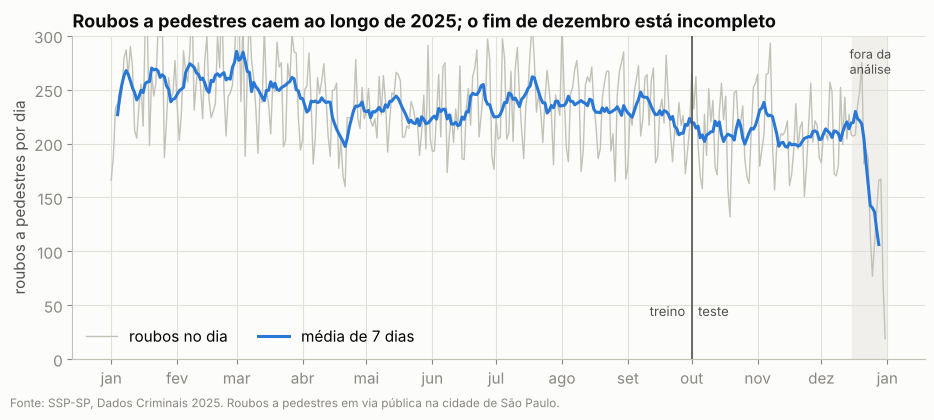

In [5]:
ssp["data"] = pd.to_datetime(ssp["DATA_OCORRENCIA_BO"], errors="coerce").dt.normalize()
ssp["registro"] = pd.to_datetime(ssp["DATA_REGISTRO"], errors="coerce").dt.normalize()
print("ano do fato:", ssp["data"].dt.year.value_counts().head(4).to_dict())
ssp = ssp[ssp["data"].dt.year == 2025]

atraso = (ssp["registro"] - ssp["data"]).dt.days
print(f"registrados mais de 7 dias depois do fato: {pct((atraso > 7).mean())} | mais de 15 dias: {pct((atraso > 15).mean())}")

por_dia = ssp.groupby("data").size().reindex(pd.date_range("2025-01-01", "2025-12-31"), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.axvspan(FIM_ANALISE + pd.Timedelta(hours=12), pd.Timestamp("2025-12-31 12:00"), color=FAIXA, zorder=0)
ax.plot(por_dia.index, por_dia, color=CINZA, linewidth=1, label="roubos no dia")
ax.plot(por_dia.index, por_dia.rolling(7, center=True).mean(), color=AZUL, linewidth=2.2, label="média de 7 dias")
ax.axvline(CORTE_TREINO_TESTE, color=TINTA_2, linewidth=1.2)
ax.text(CORTE_TREINO_TESTE - pd.Timedelta(days=3), 40, "treino", ha="right", color=TINTA_2, fontsize=9.5)
ax.text(CORTE_TREINO_TESTE + pd.Timedelta(days=3), 40, "teste", ha="left", color=TINTA_2, fontsize=9.5)
ax.text(pd.Timestamp("2025-12-24"), 290, "fora da\nanálise", ha="center", va="top", color=TINTA_2, fontsize=9)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: MESES[mdates.num2date(v).month - 1]))
ax.set_ylim(0, 300)
ax.set_ylabel("roubos a pedestres por dia")
ax.set_title("Roubos a pedestres caem ao longo de 2025; o fim de dezembro está incompleto")
ax.legend(loc="lower left", ncols=2)
fonte(fig, "Fonte: SSP-SP, Dados Criminais 2025. Roubos a pedestres em via pública na cidade de São Paulo.")
salvar(fig, "01_roubos_por_dia_2025.png")
plt.show()

ssp = ssp[ssp["data"] <= FIM_ANALISE]
etapas.append(("5. fato entre 01/01 e 15/12/2025", len(ssp)))

**Passo 6 · Hora.** Convertemos a hora para número (0 a 23). Roubos sem hora exata não entram na contagem por hora. A hora costuma ser **estimada** pela vítima (muitos horários "redondos"), por isso trabalhamos com a hora cheia, e não com o minuto.

In [6]:
hora = pd.to_datetime(ssp["HORA_OCORRENCIA_BO"], format="%H:%M:%S", errors="coerce")
sem_hora = hora.isna()
print(f"roubos sem hora exata: {sem_hora.sum():,} ({pct(sem_hora.mean())}): ficam fora da contagem por hora")
print(f"horários terminados em :00: {pct((hora[~sem_hora].dt.minute == 0).mean())} (se fosse ao acaso: {pct(1 / 60)})")

roubos_com_hora = ssp[~sem_hora].copy()
roubos_com_hora["hora"] = hora[~sem_hora].dt.hour.astype(int)
etapas.append(("6. com hora exata (entram na variável-alvo)", len(roubos_com_hora)))
pd.DataFrame(etapas, columns=["etapa do preparo", "registros"])

roubos sem hora exata: 7,960 (9,8%): ficam fora da contagem por hora
horários terminados em :00: 26,2% (se fosse ao acaso: 1,7%)


,etapa do preparo,registros
0,"extrato: capital, roubo/furto 'outros'",346702
1,2. roubo ou furto a pedestre em via pública,254472
2,3. uma linha por boletim,254444
3,4. só roubos (o alerta de assalto do app),85185
4,5. fato entre 01/01 e 15/12/2025,81455
5,6. com hora exata (entram na variável-alvo),73495


**Passo 7 · Tabela do modelo: uma linha por hora.** Contamos os roubos em cada hora de cada dia. Horas sem nenhum roubo entram com zero. Depois criamos as variáveis explicativas:

* `tipo_dia`: dia útil, sábado ou domingo/feriado (calendário de feriados de 2025 em São Paulo);
* `hora_tipo`: a hora combinada com o tipo de dia (a madrugada de sábado não é igual à de terça-feira);
* `escuro`: fração da hora que está escura, de 0 (toda clara) a 1 (toda escura). Usamos o **amanhecer** e o **anoitecer** de cada dia (início e fim do crepúsculo civil), calculados pela biblioteca `astral` para a latitude e a longitude de São Paulo. Assim, as 18h contam como escuras em junho e como claras em dezembro;
* `dias_desde_inicio`: dias desde 1º de janeiro, para captar a tendência de queda.

In [7]:
FERIADOS_2025 = pd.to_datetime([
    "2025-01-01",                  # Confraternização Universal
    "2025-01-25",                  # aniversário de São Paulo
    "2025-03-03", "2025-03-04",    # Carnaval
    "2025-04-18", "2025-04-21",    # Sexta-feira Santa e Tiradentes
    "2025-05-01",                  # Dia do Trabalho
    "2025-06-19",                  # Corpus Christi
    "2025-07-09",                  # Revolução Constitucionalista (feriado estadual)
    "2025-09-07", "2025-10-12",    # Independência e Nossa Senhora Aparecida
    "2025-11-02", "2025-11-15",    # Finados e Proclamação da República
    "2025-11-20",                  # Dia da Consciência Negra
    "2025-12-25",                  # Natal
])

dias = pd.date_range("2025-01-01", FIM_ANALISE)
grade = pd.MultiIndex.from_product([dias, range(24)], names=["data", "hora"])
base_linear = (roubos_com_hora.groupby(["data", "hora"]).size()
               .reindex(grade, fill_value=0)
               .rename("roubos")
               .reset_index())

SAO_PAULO = Observer(latitude=-23.55, longitude=-46.63)
FUSO = dt.timezone(dt.timedelta(hours=-3))          # São Paulo não tem horário de verão desde 2019


def em_horas(momento):
    return momento.hour + momento.minute / 60


horarios_sol = []
for dia in dias:
    s = sun(SAO_PAULO, date=dia.date(), tzinfo=FUSO)    # dawn = amanhecer, dusk = anoitecer
    horarios_sol.append({"data": dia, "amanhecer": em_horas(s["dawn"]), "anoitecer": em_horas(s["dusk"])})
sol = pd.DataFrame(horarios_sol).set_index("data")
base_linear = base_linear.join(sol, on="data")

hora_ini = base_linear["hora"]
base_linear["escuro"] = (np.clip(base_linear["amanhecer"] - hora_ini, 0, 1)          # parte antes do amanhecer
                         + np.clip(hora_ini + 1 - base_linear["anoitecer"], 0, 1)    # parte depois do anoitecer
                         ).clip(0, 1)
dia_da_semana = base_linear["data"].dt.dayofweek
base_linear["tipo_dia"] = np.select(
    [base_linear["data"].isin(FERIADOS_2025) | (dia_da_semana == 6), dia_da_semana == 5],
    ["domingo/feriado", "sábado"], default="dia útil")
base_linear["hora_tipo"] = base_linear["hora"].map("{:02d}h".format) + " · " + base_linear["tipo_dia"]
base_linear["dias_desde_inicio"] = (base_linear["data"] - pd.Timestamp("2025-01-01")).dt.days

print(f"{len(base_linear):,} horas ({len(dias)} dias x 24) | média de {num(base_linear['roubos'].mean(), 1)} roubos por hora")
base_linear[["data", "hora", "tipo_dia", "hora_tipo", "escuro", "dias_desde_inicio", "roubos"]].sample(5, random_state=1)

8,376 horas (349 dias x 24) | média de 8,8 roubos por hora


,data,hora,tipo_dia,hora_tipo,escuro,dias_desde_inicio,roubos
2065,2025-03-28,1,dia útil,01h · dia útil,1.00,86,7
1117,2025-02-16,13,domingo/feriado,13h · domingo/feriado,0.00,46,5
7492,2025-11-09,4,domingo/feriado,04h · domingo/feriado,0.85,312,12
946,2025-02-09,10,domingo/feriado,10h · domingo/feriado,0.00,39,6
3532,2025-05-28,4,dia útil,04h · dia útil,1.00,147,12


**Exploração (só com os dados de treino, jan–set).** O padrão por hora muda com o tipo de dia, o que justifica combinar hora e tipo de dia em uma só variável. Para não "espiar" o teste, a exploração usa só o período de treino.

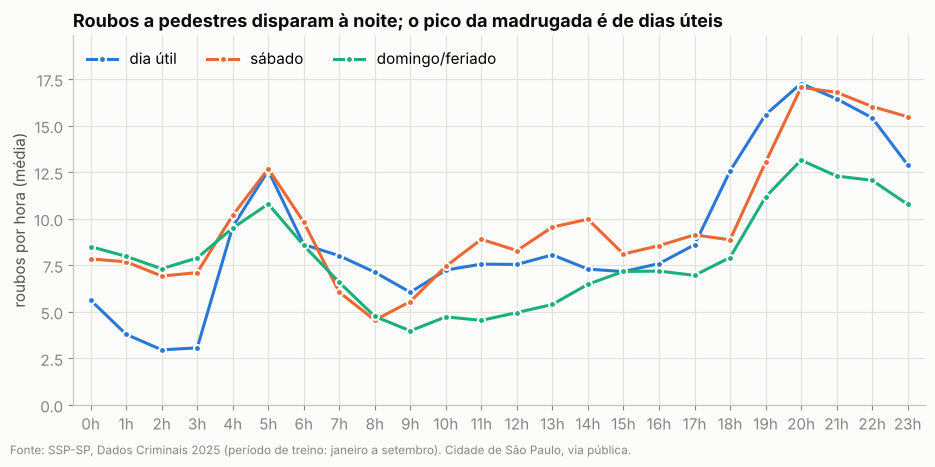

In [8]:
explorar = base_linear[base_linear["data"] < CORTE_TREINO_TESTE]
perfil = explorar.pivot_table(index="hora", columns="tipo_dia", values="roubos", aggfunc="mean")

fig, ax = plt.subplots(figsize=(11, 4.8))
for tipo, cor in [("dia útil", AZUL), ("sábado", LARANJA), ("domingo/feriado", VERDE_AGUA)]:
    ax.plot(perfil.index, perfil[tipo], color=cor, linewidth=2.2, marker="o", markersize=5,
            markeredgecolor=FUNDO, markeredgewidth=1.5, label=tipo)
ax.set_xticks(range(24), [f"{h}h" for h in range(24)])
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(0, perfil.to_numpy().max() * 1.15)
ax.set_ylabel("roubos por hora (média)")
ax.set_title("Roubos a pedestres disparam à noite; o pico da madrugada é de dias úteis")
ax.legend(loc="upper left", ncols=3)
fonte(fig, "Fonte: SSP-SP, Dados Criminais 2025 (período de treino: janeiro a setembro). Cidade de São Paulo, via pública.")
salvar(fig, "02_roubos_por_hora_e_tipo_de_dia.png")
plt.show()

### 4.2 Pedidos ao SP156 → base da regressão logística

**Passo 1 · Nulos, datas e subprefeitura.** As datas vêm no formato brasileiro. A coluna de subprefeitura tem grafias alternativas ("CASA VERDE-LIMAO-CACHOEIRINHA", "PERUS-ANHANGUERA") e nomes que não são subprefeitura (órgãos, "Prefeitura Regional não encontrada"): unificamos as grafias e deixamos os demais como nulo.

In [9]:
sp156_bruto = ler_base("sp156_rua_e_bairro_2025")
print(f"{len(sp156_bruto):,} linhas x {sp156_bruto.shape[1]} colunas")
sp156 = sp156_bruto.replace({"": np.nan})

sp156["abertura"] = pd.to_datetime(sp156["Data de Abertura"], format="%d/%m/%Y", errors="coerce")
sp156["finalizacao"] = pd.to_datetime(sp156["Data de Finalização"], format="%d/%m/%Y", errors="coerce")
print("data de abertura inválida:", sp156["abertura"].isna().sum())

SUBPREFEITURAS = [
    "ARICANDUVA-FORMOSA-CARRAO", "BUTANTA", "CAMPO LIMPO", "CAPELA DO SOCORRO", "CASA VERDE-CACHOEIRINHA",
    "CIDADE ADEMAR", "CIDADE TIRADENTES", "ERMELINO MATARAZZO", "FREGUESIA-BRASILANDIA", "GUAIANASES",
    "IPIRANGA", "ITAIM PAULISTA", "ITAQUERA", "JABAQUARA", "JACANA-TREMEMBE", "LAPA", "M BOI MIRIM", "MOOCA",
    "PARELHEIROS", "PENHA", "PERUS", "PINHEIROS", "PIRITUBA-JARAGUA", "SANTANA-TUCURUVI", "SANTO AMARO",
    "SAO MATEUS", "SAO MIGUEL", "SAPOPEMBA", "SE", "VILA MARIA-VILA GUILHERME", "VILA MARIANA", "VILA PRUDENTE",
]
sp156["subprefeitura"] = sp156["Prefeitura Operacional"].replace(
    {"CASA VERDE-LIMAO-CACHOEIRINHA": "CASA VERDE-CACHOEIRINHA", "PERUS-ANHANGUERA": "PERUS"})
print("valores que não são subprefeitura:",
      sp156.loc[~sp156["subprefeitura"].isin(SUBPREFEITURAS), "subprefeitura"].value_counts(dropna=False).to_dict())
sp156.loc[~sp156["subprefeitura"].isin(SUBPREFEITURAS), "subprefeitura"] = np.nan

336,555 linhas x 10 colunas
data de abertura inválida: 0


valores que não são subprefeitura: {'Superintendencia das Usinas de Asfalto': 1234, nan: 435, 'Prefeitura Regional nao encontrada': 274, 'Departamento de Aguas e Energia Eletrica': 11, 'Secretaria Municipal do Verde e do Meio Ambiente': 3, 'Departamento de Estradas de Rodagem': 2}


**Passo 2 · Do SP156 para as categorias do app.** Ficam só os serviços que correspondem a categorias de alerta do Caminho Livre. "Rua escura" não entra porque o SP156 de 2025 não tem nenhum serviço de iluminação pública.

| Categoria no app | Serviços do SP156 |
|---|---|
| Buraco | tapa-buraco; tapa-buraco em corredor de ônibus |
| Calçada quebrada | manutenção de calçada pública; calçada particular danificada ou inexistente |
| Obstáculo na calçada | avaliação de obstáculo na calçada (acessibilidade) |
| Falta de rampa | rebaixamento de guia para travessia de pedestres |
| Alagamento | limpeza de bueiro; bueiro e boca de lobo; reforma de galeria pluvial; microdrenagem |
| Degrau (escadaria ou viela) | manutenção de vielas e escadarias |

**Passo 3 · Variável-alvo.** `persiste_15d = 1` quando o pedido **não** foi finalizado em até 15 dias (continuava aberto, em andamento ou foi finalizado depois). Como os dados foram gerados em agosto de 2026, todo pedido de 2025 teve bem mais que 15 dias de acompanhamento: a resposta é conhecida para todos. Pedidos **cancelados pelo próprio cidadão** saem, porque não dizem se o problema foi resolvido.

In [10]:
SERVICOS = {   # nome no SP156: (nome curto, categoria no app)
    "Tapa-buraco": ("Tapa-buraco", "Buraco"),
    "Tapa-buraco em faixa exclusiva ou corredor de ônibus": ("Tapa-buraco em corredor de ônibus", "Buraco"),
    "Calçada pública - solicitar manutenção": ("Calçada pública: manutenção", "Calçada quebrada"),
    "Calçada particular - denunciar calçada danificada ou inexistente": ("Calçada particular danificada", "Calçada quebrada"),
    "Acessibilidade - solicitar avaliação de obstáculo na calçada": ("Obstáculo na calçada", "Obstáculo na calçada"),
    "Guias para travessia de pedestres - Solicitar rebaixamento": ("Rebaixamento de guia", "Falta de rampa"),
    "Solicitar limpeza de bueiros, boca de lobo e poços de visita": ("Limpeza de bueiro", "Alagamento"),
    "Drenagem de água da chuva - Bueiros e bocas de lobo": ("Bueiro e boca de lobo", "Alagamento"),
    "Reformar galerias de águas de chuvas (pluviais)": ("Reforma de galeria pluvial", "Alagamento"),
    "Microdrenagem": ("Microdrenagem", "Alagamento"),
    "Vielas e escadarias - solicitar manutenção": ("Viela ou escadaria", "Degrau (escadaria ou viela)"),
}
etapas156 = [("extrato: tema 'Rua e bairro' em 2025", len(sp156))]

pedidos = sp156[sp156["Serviço"].isin(list(SERVICOS))]
etapas156.append(("1. serviços que existem como categoria no app", len(pedidos)))
print("status:", pedidos["Status"].value_counts().to_dict())

pedidos = pedidos[pedidos["Status"] != "Cancelada"]
etapas156.append(("2. sem pedidos cancelados pelo cidadão", len(pedidos)))
pedidos = pedidos.dropna(subset=["subprefeitura"])
etapas156.append(("3. com subprefeitura válida", len(pedidos)))

finalizado_sem_data = (pedidos["Status"] == "Finalizada") & pedidos["finalizacao"].isna()
print("finalizados sem data de finalização (saem):", finalizado_sem_data.sum())
pedidos = pedidos[~finalizado_sem_data].copy()
etapas156.append(("4. sem 'Finalizada' sem data de finalização", len(pedidos)))
dias_ate_finalizar = (pedidos["finalizacao"] - pedidos["abertura"]).dt.days
print("datas inconsistentes (fim antes do início):", (dias_ate_finalizar < 0).sum())

resolvido_em_15_dias = (pedidos["Status"] == "Finalizada") & (dias_ate_finalizar <= 15)
pedidos["persiste_15d"] = (~resolvido_em_15_dias).astype(int)
pedidos["servico"] = pedidos["Serviço"].map(lambda s: SERVICOS[s][0])
pedidos["categoria_app"] = pedidos["Serviço"].map(lambda s: SERVICOS[s][1])
pedidos["dia_semana"] = pedidos["abertura"].dt.dayofweek.map(dict(enumerate(DIAS)))

print(f"\nbase da regressão logística: {len(pedidos):,} pedidos | persiste_15d = 1 em {pct(pedidos['persiste_15d'].mean())}")
display(pd.DataFrame(etapas156, columns=["etapa do preparo", "pedidos"]))
pedidos[["abertura", "servico", "categoria_app", "subprefeitura", "dia_semana", "persiste_15d"]].sample(5, random_state=1)

status: {'Finalizada': 162138, 'Aberto': 12658, 'Cancelada': 884, 'Em Andamento': 69}
finalizados sem data de finalização (saem): 19


datas inconsistentes (fim antes do início): 0



base da regressão logística: 173,783 pedidos | persiste_15d = 1 em 31,6%


,etapa do preparo,pedidos
0,extrato: tema 'Rua e bairro' em 2025,336555
1,1. serviços que existem como categoria no app,175749
2,2. sem pedidos cancelados pelo cidadão,174865
3,3. com subprefeitura válida,173802
4,4. sem 'Finalizada' sem data de finalização,173783


,abertura,servico,categoria_app,subprefeitura,dia_semana,persiste_15d
136299,2025-04-27,Calçada pública: manutenção,Calçada quebrada,CASA VERDE-CACHOEIRINHA,dom,0
76715,2025-03-17,Limpeza de bueiro,Alagamento,MOOCA,seg,0
78426,2025-02-18,Tapa-buraco,Buraco,LAPA,ter,1
164462,2025-06-08,Tapa-buraco,Buraco,CAPELA DO SOCORRO,dom,0
232165,2025-09-10,Obstáculo na calçada,Obstáculo na calçada,SAO MATEUS,qua,1


**Exploração (só com os dados de treino).** A chance de o problema continuar depois de 15 dias muda muito de uma categoria para outra: o serviço pedido deve ser a variável mais importante do modelo.

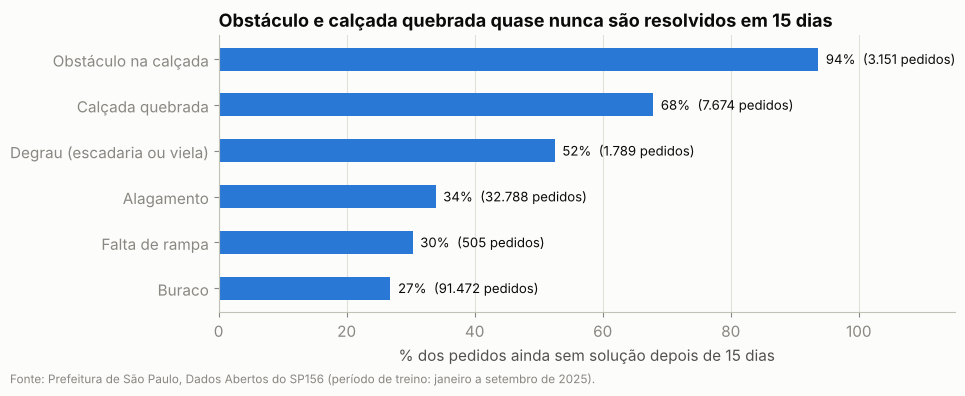

In [11]:
explorar = pedidos[pedidos["abertura"] < CORTE_TREINO_TESTE]
taxa = explorar.groupby("categoria_app")["persiste_15d"].agg(["mean", "size"]).sort_values("mean")

fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.barh(taxa.index, taxa["mean"] * 100, color=AZUL, height=0.5)
for i, (valor, n) in enumerate(zip(taxa["mean"], taxa["size"])):
    ax.text(valor * 100 + 1.2, i, f"{pct(valor, 0)}  ({n:,} pedidos)".replace(",", "."), va="center", color=TINTA, fontsize=9.5)
ax.set_xlim(0, 115)
ax.set_xticks(range(0, 101, 20))
ax.grid(axis="y", visible=False)
ax.set_xlabel("% dos pedidos ainda sem solução depois de 15 dias")
ax.set_title("Obstáculo e calçada quebrada quase nunca são resolvidos em 15 dias")
fonte(fig, "Fonte: Prefeitura de São Paulo, Dados Abertos do SP156 (período de treino: janeiro a setembro de 2025).")
salvar(fig, "03_persistencia_por_categoria.png")
plt.show()

### 4.3 Separação entre treino e teste, sem vazamento de dados

**Como dividimos:** pela **data**, nos dois modelos. O modelo aprende com **janeiro a setembro de 2025** (treino) e é avaliado em **outubro a dezembro de 2025** (teste), como se estivesse prevendo o futuro. Uma divisão aleatória misturaria dias vizinhos e semanas parecidas entre treino e teste, e o resultado pareceria melhor do que é.

**Cuidados contra vazamento de dados:**

1. **Nada do futuro:** todo o teste é posterior a todo o treino (conferido abaixo).
2. **Nada que dependa da resposta:** `Status`, `Data de Finalização` e o tempo até finalizar **não entram** como variáveis, porque só se conhecem depois. O mesmo vale para o órgão responsável, que pode mudar durante o atendimento (nem está no extrato).
3. **Preparo aprendido só no treino:** a transformação das categorias em colunas 0/1 (*one-hot*) fica dentro de um `Pipeline` do scikit-learn, que a ajusta só com os dados de treino.
4. **Limiar da regressão logística escolhido sem o teste:** usamos uma validação dentro do próprio treino (seção 6).
5. **Variáveis conhecidas na hora da previsão:** hora, tipo de dia, horário do sol (calculado por astronomia), data, serviço pedido, subprefeitura e dia da semana.
6. **Exploração só no treino:** os gráficos que ajudaram a escolher as variáveis (seções 4.1 e 4.2) usaram só jan–set.

In [12]:
X_LINEAR = ["hora_tipo", "escuro", "dias_desde_inicio"]
X_LOGISTICA = ["servico", "subprefeitura", "dia_semana"]

treino_lin = base_linear[base_linear["data"] < CORTE_TREINO_TESTE]
teste_lin = base_linear[base_linear["data"] >= CORTE_TREINO_TESTE]
treino_log = pedidos[pedidos["abertura"] < CORTE_TREINO_TESTE]
teste_log = pedidos[pedidos["abertura"] >= CORTE_TREINO_TESTE]

# Conferências automáticas: o notebook para com erro se alguma regra for quebrada
assert treino_lin["data"].max() < teste_lin["data"].min()
assert treino_log["abertura"].max() < teste_log["abertura"].min()
assert not {"Status", "Data de Finalização", "finalizacao", "persiste_15d"} & set(X_LOGISTICA)
assert "roubos" not in X_LINEAR
print("OK: todo o teste é posterior ao treino e nenhuma variável usa a resposta.")


def resumo(nome, conjunto, datas, alvo):
    return {"modelo": nome, "conjunto": conjunto, "de": datas.min().strftime("%d/%m/%Y"),
            "até": datas.max().strftime("%d/%m/%Y"), "linhas": len(alvo), "média da variável-alvo": round(alvo.mean(), 3)}


pd.DataFrame([
    resumo("linear (roubos por hora)", "treino", treino_lin["data"], treino_lin["roubos"]),
    resumo("linear (roubos por hora)", "teste", teste_lin["data"], teste_lin["roubos"]),
    resumo("logística (persiste_15d)", "treino", treino_log["abertura"], treino_log["persiste_15d"]),
    resumo("logística (persiste_15d)", "teste", teste_log["abertura"], teste_log["persiste_15d"]),
]).set_index(["modelo", "conjunto"])

OK: todo o teste é posterior ao treino e nenhuma variável usa a resposta.


de         até  linhas  \
modelo                   conjunto                                   
linear (roubos por hora) treino    01/01/2025  30/09/2025    6552   
                         teste     01/10/2025  15/12/2025    1824   
logística (persiste_15d) treino    01/01/2025  30/09/2025  137379   
                         teste     01/10/2025  31/12/2025   36404   

                                   média da variável-alvo  
modelo                   conjunto                          
linear (roubos por hora) treino                     9.002  
                         teste                      7.956  
logística (persiste_15d) treino                     0.327  
                         teste                      0.273

## 5. Regressão linear: quantos roubos a pedestres em cada hora?

**Modelo:** `roubos = b0 + b(hora_tipo) + b1·escuro + b2·dias_desde_inicio + erro`

* `hora_tipo` vira 72 colunas 0/1 (24 horas x 3 tipos de dia). Uma delas fica de fora (`drop="first"`), como referência, para os coeficientes não ficarem redundantes com o intercepto.
* `escuro` e `dias_desde_inicio` entram como números.

**Referência para comparar:** prever sempre a **média do treino** (um "modelo" que não sabe nada). Se a regressão não for bem melhor que isso, ela não serve.

**Métricas no teste:**

* **MAE** (erro absoluto médio): quantos roubos por hora o modelo erra, em média;
* **RMSE** (raiz do erro quadrático médio): parecido com o MAE, mas pune mais os erros grandes;
* **R²**: que fração da variação de uma hora para outra o modelo explica (0 = nada, 1 = tudo).

In [13]:
modelo_linear = Pipeline([
    ("preparo", ColumnTransformer([("categorias", OneHotEncoder(drop="first"), ["hora_tipo"])],
                                  remainder="passthrough")),
    ("regressao", LinearRegression()),
])
modelo_linear.fit(treino_lin[X_LINEAR], treino_lin["roubos"])
previsto_treino = modelo_linear.predict(treino_lin[X_LINEAR])
previsto_teste = modelo_linear.predict(teste_lin[X_LINEAR])


def metricas_regressao(real, previsto):
    return {"MAE": mean_absolute_error(real, previsto),
            "RMSE": np.sqrt(mean_squared_error(real, previsto)),
            "R²": r2_score(real, previsto)}


media_treino = np.full(len(teste_lin), treino_lin["roubos"].mean())
metricas_lin = pd.DataFrame({
    "referência: média do treino (teste)": metricas_regressao(teste_lin["roubos"], media_treino),
    "regressão linear (treino)": metricas_regressao(treino_lin["roubos"], previsto_treino),
    "regressão linear (teste)": metricas_regressao(teste_lin["roubos"], previsto_teste),
}).T
print("previsões negativas no teste:", (previsto_teste < 0).sum())
metricas_lin.round(3)

previsões negativas no teste: 0


,MAE,RMSE,R²
referência: média do treino (teste),4.200,5.314,-0.040
regressão linear (treino),2.896,3.845,0.494
regressão linear (teste),2.844,3.745,0.483


In [14]:
nomes = modelo_linear.named_steps["preparo"].get_feature_names_out()
coeficientes = pd.Series(modelo_linear.named_steps["regressao"].coef_, index=nomes)
b_escuro = coeficientes["remainder__escuro"]
b_tendencia = coeficientes["remainder__dias_desde_inicio"]
media_18h = treino_lin.loc[treino_lin["hora"] == 18, "roubos"].mean()

# Quanto do R² é possível? Contagens pequenas oscilam por acaso em torno da média (ruído de Poisson,
# variância = média). Descontando esse acaso, o R² máximo que algum modelo conseguiria é aproximadamente:
teto_r2 = 1 - teste_lin["roubos"].mean() / teste_lin["roubos"].var()

print(f"escuro:            {num(b_escuro):>6} roubo por hora quando a hora está toda escura (mesma hora e mesmo tipo de dia)")
print(f"                   às 18h, a média é de {num(media_18h, 1)} roubos/hora: o escuro soma {pct(b_escuro / media_18h, 0)}")
print(f"dias_desde_inicio: {num(b_tendencia, 4):>6} por dia = {num(b_tendencia * 30)} roubo/hora a cada 30 dias")
print(f"R² máximo possível (descontado o acaso das contagens): cerca de {num(teto_r2)}")

escuro:              1,72 roubo por hora quando a hora está toda escura (mesma hora e mesmo tipo de dia)
                   às 18h, a média é de 11,2 roubos/hora: o escuro soma 15%
dias_desde_inicio: -0,0049 por dia = -0,15 roubo/hora a cada 30 dias
R² máximo possível (descontado o acaso das contagens): cerca de 0,71


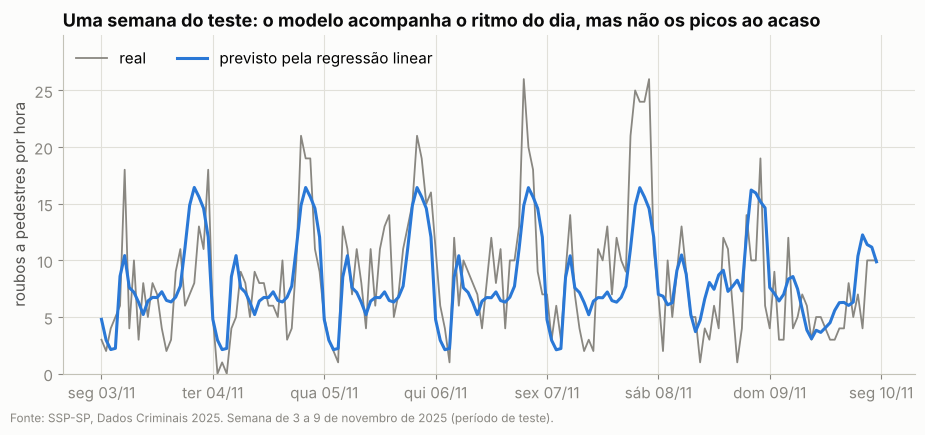

In [15]:
semana = teste_lin[(teste_lin["data"] >= "2025-11-03") & (teste_lin["data"] <= "2025-11-09")]
instantes = semana["data"] + pd.to_timedelta(semana["hora"], unit="h")
previsto_semana = modelo_linear.predict(semana[X_LINEAR])

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(instantes, semana["roubos"], color=TINTA_SUAVE, linewidth=1.3, label="real")
ax.plot(instantes, previsto_semana, color=AZUL, linewidth=2.2, label="previsto pela regressão linear")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{DIAS[mdates.num2date(v).weekday()]} {mdates.num2date(v).day:02d}/11"))
ax.set_ylabel("roubos a pedestres por hora")
ax.set_ylim(0, max(semana["roubos"].max(), previsto_semana.max()) * 1.15)
ax.set_title("Uma semana do teste: o modelo acompanha o ritmo do dia, mas não os picos ao acaso")
ax.legend(loc="upper left", ncols=2)
fonte(fig, "Fonte: SSP-SP, Dados Criminais 2025. Semana de 3 a 9 de novembro de 2025 (período de teste).")
salvar(fig, "04_linear_semana_real_vs_previsto.png")
plt.show()

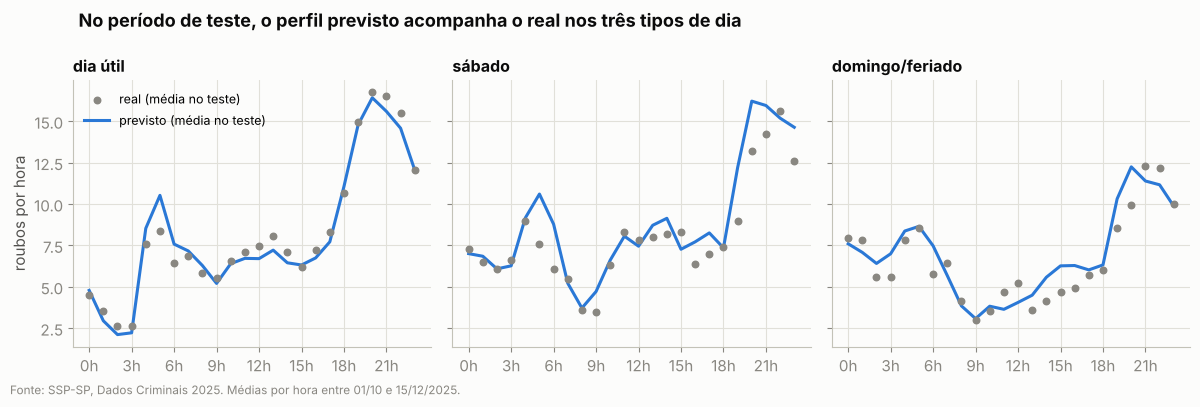

In [16]:
teste_lin_prev = teste_lin.assign(previsto=previsto_teste)
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.9), sharey=True)
for ax, tipo in zip(eixos, ["dia útil", "sábado", "domingo/feriado"]):
    grupo = teste_lin_prev[teste_lin_prev["tipo_dia"] == tipo].groupby("hora")[["roubos", "previsto"]].mean()
    ax.scatter(grupo.index, grupo["roubos"], color=TINTA_SUAVE, s=22, label="real (média no teste)", zorder=3)
    ax.plot(grupo.index, grupo["previsto"], color=AZUL, linewidth=2.2, label="previsto (média no teste)")
    ax.set_title(tipo, fontsize=11.5)
    ax.set_xticks(range(0, 24, 3), [f"{h}h" for h in range(0, 24, 3)])
eixos[0].set_ylabel("roubos por hora")
eixos[0].legend(loc="upper left", fontsize=9)
fig.suptitle("No período de teste, o perfil previsto acompanha o real nos três tipos de dia",
             x=0.06, ha="left", fontweight="bold", color=TINTA, fontsize=13)
fig.tight_layout()
fonte(fig, "Fonte: SSP-SP, Dados Criminais 2025. Médias por hora entre 01/10 e 15/12/2025.")
salvar(fig, "05_linear_perfil_previsto_por_hora.png")
plt.show()

**Interpretação da regressão linear**

* **Bem melhor que a referência.** Prevendo sempre a média, o erro médio seria de 4,2 roubos por hora e o R² ficaria perto de zero. A regressão erra em média **2,84 roubos por hora (MAE)** e explica **48% da variação** de uma hora para outra (R² = 0,48).
* **Sem sobreajuste.** O R² no teste (0,483) é quase igual ao do treino (0,494): o modelo aprendeu um padrão que se repete em meses que ele não viu.
* **R² de 0,48 é bom para esse tipo de dado.** Contagens pequenas variam por acaso: mesmo sabendo a média exata de uma hora, o número observado oscila em torno dela. Descontado esse acaso, o máximo que algum modelo conseguiria é por volta de **0,71**; o nosso chega a cerca de dois terços disso. O **RMSE (3,75) maior que o MAE (2,84)** mostra que os maiores erros estão nos picos ao acaso, como os da sexta e do sábado no gráfico da semana.
* **Coeficientes:**
  * `escuro` = **+1,72**: comparando a mesma hora e o mesmo tipo de dia, uma hora toda escura tem cerca de 1,7 roubo a mais. Às 18h, isso é **15% a mais**. Ou seja, **a escuridão aumenta o risco**, e não só o horário do relógio.
  * `dias_desde_inicio` = **−0,0049 por dia**: cerca de 0,15 roubo/hora a menos a cada 30 dias, a queda vista no gráfico de 2025.
  * `hora_tipo`: o perfil do dia. O pico é entre **19h e 22h** (cerca de 17 roubos/hora nos dias úteis), com um segundo pico às **5h**, de quem sai cedo para trabalhar.

## 6. Regressão logística: o problema ainda estará lá depois de 15 dias?

**Modelo:** a regressão logística estima a **probabilidade** de `persiste_15d = 1` a partir do serviço pedido, da subprefeitura e do dia da semana (todos viram colunas 0/1). As referências (`drop`) são o **tapa-buraco**, a subprefeitura da **Sé** e a **segunda-feira**, para que cada coeficiente compare com elas.

**De probabilidade para "sim ou não":** o modelo diz "persiste" quando a probabilidade passa de um **limiar**. O padrão é 50%, mas para o app errar para menos é pior: um alerta que some do mapa enquanto o buraco ou a calçada quebrada continuam lá deixa o cidadão sem aviso. Por isso escolhemos o limiar que dá o melhor **F1** (equilíbrio entre precisão e recall) em uma **validação dentro do treino**: o modelo aprende com janeiro a julho e testa limiares em agosto e setembro. O teste (out–dez) não é usado nessa escolha.

**Métricas no teste** (classe positiva = "ainda sem solução depois de 15 dias"):

* **matriz de confusão**: acertos e erros de cada tipo;
* **precisão**: dos pedidos que o modelo marcou como "persiste", quantos persistiram de fato;
* **recall**: dos pedidos que persistiram, quantos o modelo encontrou;
* **F1**: média harmônica entre precisão e recall.

limiar escolhido na validação (ago–set): 0,45 (F1 de validação = 0,485)


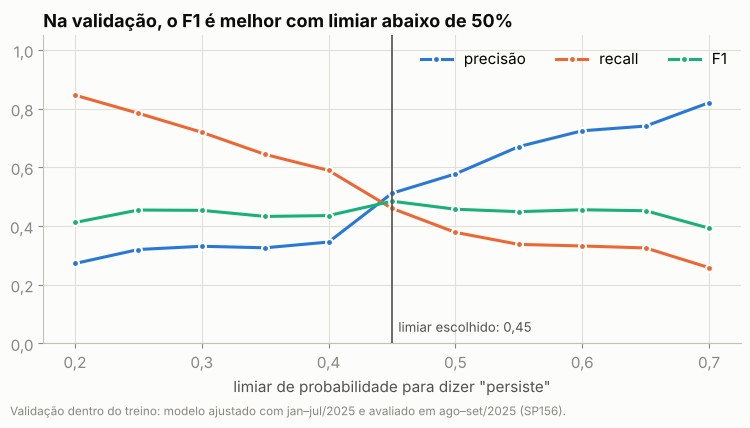

In [17]:
def novo_modelo_logistico():
    return Pipeline([
        ("preparo", ColumnTransformer([("categorias",
                                        OneHotEncoder(drop=["Tapa-buraco", "SE", "seg"], handle_unknown="ignore"),
                                        X_LOGISTICA)])),
        ("regressao", LogisticRegression(max_iter=2000)),
    ])


CORTE_VALIDACAO = pd.Timestamp("2025-08-01")
sub_treino = treino_log[treino_log["abertura"] < CORTE_VALIDACAO]
validacao = treino_log[treino_log["abertura"] >= CORTE_VALIDACAO]
modelo_validacao = novo_modelo_logistico().fit(sub_treino[X_LOGISTICA], sub_treino["persiste_15d"])
prob_validacao = modelo_validacao.predict_proba(validacao[X_LOGISTICA])[:, 1]

limiares = np.round(np.arange(0.20, 0.71, 0.05), 2)
y_validacao = validacao["persiste_15d"]
curva = pd.DataFrame({
    "precisão": [precision_score(y_validacao, (prob_validacao >= l).astype(int), zero_division=0) for l in limiares],
    "recall": [recall_score(y_validacao, (prob_validacao >= l).astype(int)) for l in limiares],
    "F1": [f1_score(y_validacao, (prob_validacao >= l).astype(int), zero_division=0) for l in limiares],
}, index=limiares)
LIMIAR = float(curva["F1"].idxmax())
print(f"limiar escolhido na validação (ago–set): {num(LIMIAR)} (F1 de validação = {num(curva['F1'].max(), 3)})")

fig, ax = plt.subplots(figsize=(9, 4))
for coluna, cor in [("precisão", AZUL), ("recall", LARANJA), ("F1", VERDE_AGUA)]:
    ax.plot(curva.index, curva[coluna], color=cor, linewidth=2.2, marker="o", markersize=5,
            markeredgecolor=FUNDO, markeredgewidth=1.5, label=coluna)
ax.axvline(LIMIAR, color=TINTA_2, linewidth=1.2)
ax.text(LIMIAR + 0.005, 0.04, f"limiar escolhido: {num(LIMIAR)}", color=TINTA_2, fontsize=9.5)
ax.set_ylim(0, 1.05)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v, 1)))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v, 1)))
ax.set_xlabel("limiar de probabilidade para dizer \"persiste\"")
ax.set_title("Na validação, o F1 é melhor com limiar abaixo de 50%")
ax.legend(loc="upper right", ncols=3)
fonte(fig, "Validação dentro do treino: modelo ajustado com jan–jul/2025 e avaliado em ago–set/2025 (SP156).")
salvar(fig, "06_logistica_escolha_do_limiar.png")
plt.show()

In [18]:
modelo_logistico = novo_modelo_logistico().fit(treino_log[X_LOGISTICA], treino_log["persiste_15d"])
prob_teste = modelo_logistico.predict_proba(teste_log[X_LOGISTICA])[:, 1]
y_teste = teste_log["persiste_15d"]


def metricas_classificacao(previsto, prob=None):
    return {"acurácia": accuracy_score(y_teste, previsto),
            "precisão": precision_score(y_teste, previsto, zero_division=0),
            "recall": recall_score(y_teste, previsto),
            "F1": f1_score(y_teste, previsto, zero_division=0),
            "AUC": roc_auc_score(y_teste, prob) if prob is not None else np.nan}


previsto_logistica = (prob_teste >= LIMIAR).astype(int)
metricas_log = pd.DataFrame({
    "referência: sempre 'resolvido' (0)": metricas_classificacao(np.zeros(len(y_teste), dtype=int)),
    "referência: sempre 'persiste' (1)": metricas_classificacao(np.ones(len(y_teste), dtype=int)),
    "regressão logística, limiar 0,50": metricas_classificacao((prob_teste >= 0.5).astype(int), prob_teste),
    f"regressão logística, limiar {num(LIMIAR)} (escolhido)": metricas_classificacao(previsto_logistica, prob_teste),
}).T
print(f"teste: {len(y_teste):,} pedidos, {pct(y_teste.mean())} persistiram")
metricas_log.round(3)

teste: 36,404 pedidos, 27,3% persistiram


,acurácia,precisão,recall,F1,AUC
referência: sempre 'resolvido' (0),0.727,0.000,0.000,0.000,NaN
referência: sempre 'persiste' (1),0.273,0.273,1.000,0.429,NaN
"regressão logística, limiar 0,50",0.798,0.765,0.377,0.505,0.722
"regressão logística, limiar 0,45 (escolhido)",0.786,0.660,0.446,0.532,0.722


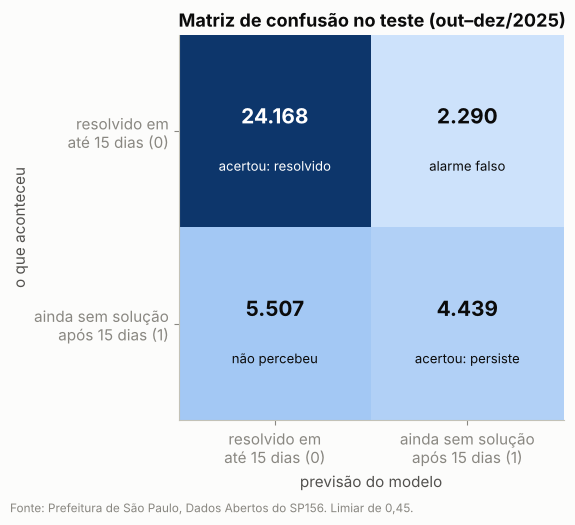

Os 5,507 casos que persistiram mas o modelo não percebeu, por categoria:


,% dos casos não percebidos
categoria_app,
Buraco,"73,9%"
Alagamento,"21,2%"
Calçada quebrada,"4,0%"
Falta de rampa,"0,5%"
Degrau (escadaria ou viela),"0,5%"


In [19]:
matriz = confusion_matrix(y_teste, previsto_logistica, labels=[0, 1])
legendas = [["acertou: resolvido", "alarme falso"], ["não percebeu", "acertou: persiste"]]

fig, ax = plt.subplots(figsize=(6.4, 5))
ax.imshow(matriz, cmap=AZUIS)
for i in range(2):
    for j in range(2):
        cor = "white" if matriz[i, j] > matriz.max() * 0.45 else TINTA
        ax.text(j, i - 0.08, f"{matriz[i, j]:,}".replace(",", "."), ha="center", va="center",
                color=cor, fontsize=15, fontweight="bold")
        ax.text(j, i + 0.18, legendas[i][j], ha="center", va="center", color=cor, fontsize=9.5)
rotulos = ["resolvido em\naté 15 dias (0)", "ainda sem solução\napós 15 dias (1)"]
ax.set_xticks([0, 1], rotulos)
ax.set_yticks([0, 1], rotulos)
ax.set_xlabel("previsão do modelo")
ax.set_ylabel("o que aconteceu")
ax.grid(False)
ax.set_title("Matriz de confusão no teste (out–dez/2025)")
fonte(fig, f"Fonte: Prefeitura de São Paulo, Dados Abertos do SP156. Limiar de {num(LIMIAR)}.")
salvar(fig, "07_logistica_matriz_de_confusao.png")
plt.show()

nao_percebeu = teste_log[(y_teste == 1) & (previsto_logistica == 0)]
print(f"Os {len(nao_percebeu):,} casos que persistiram mas o modelo não percebeu, por categoria:")
nao_percebeu["categoria_app"].value_counts(normalize=True).map(pct).to_frame("% dos casos não percebidos")

In [20]:
nomes = modelo_logistico.named_steps["preparo"].get_feature_names_out()
razao_chances = pd.Series(np.exp(modelo_logistico.named_steps["regressao"].coef_[0]), index=nomes)
servicos = (razao_chances[razao_chances.index.str.startswith("categorias__servico_")]
            .rename(lambda n: n.replace("categorias__servico_", "")).sort_values())
subprefeituras = (razao_chances[razao_chances.index.str.startswith("categorias__subprefeitura_")]
                  .rename(lambda n: n.replace("categorias__subprefeitura_", "")).sort_values())
print("Razão de chances de PERSISTIR depois de 15 dias, comparando com o tapa-buraco (= 1):")
display(servicos.sort_values(ascending=False).round(2).to_frame("razão de chances"))
print("Subprefeituras, comparando com a Sé (= 1): acima de 1, o problema tende a demorar mais")
mais_lentas = subprefeituras.sort_values(ascending=False).head(5)
mais_rapidas = subprefeituras.sort_values().head(5)
pd.DataFrame({"mais lentas": mais_lentas.index, "razão (lentas)": mais_lentas.round(2).to_numpy(),
              "mais rápidas": mais_rapidas.index, "razão (rápidas)": mais_rapidas.round(2).to_numpy()})

Razão de chances de PERSISTIR depois de 15 dias, comparando com o tapa-buraco (= 1):


,razão de chances
Obstáculo na calçada,48.87
Calçada particular danificada,47.73
Microdrenagem,12.68
Bueiro e boca de lobo,4.37
Reforma de galeria pluvial,3.74
Viela ou escadaria,3.73
Calçada pública: manutenção,3.08
Rebaixamento de guia,1.31
Limpeza de bueiro,0.75
Tapa-buraco em corredor de ônibus,0.45


Subprefeituras, comparando com a Sé (= 1): acima de 1, o problema tende a demorar mais


,mais lentas,razão (lentas),mais rápidas,razão (rápidas)
0,LAPA,1.31,JABAQUARA,0.13
1,ITAIM PAULISTA,1.28,VILA PRUDENTE,0.20
2,PIRITUBA-JARAGUA,1.18,VILA MARIA-VILA GUILHERME,0.22
3,PINHEIROS,1.06,JACANA-TREMEMBE,0.24
4,SAO MIGUEL,0.85,SANTANA-TUCURUVI,0.25


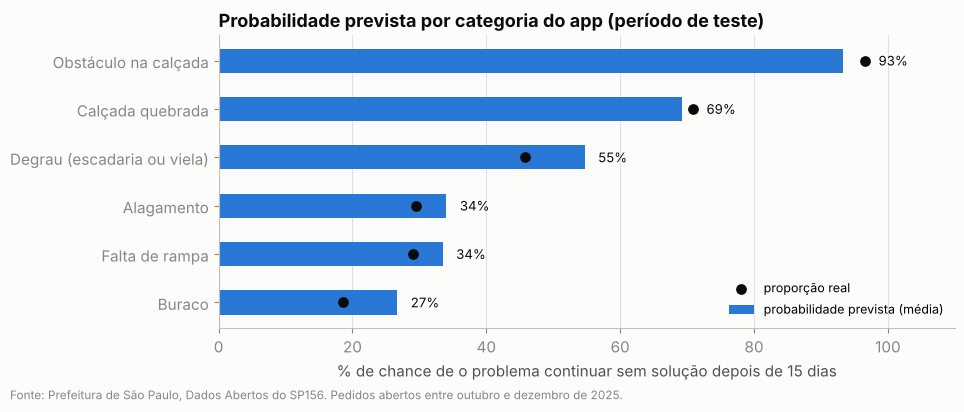

,previsto,real,pedidos
categoria_app,,,
Buraco,"26,7%","18,6%",23045
Falta de rampa,"33,5%","29,1%",141
Alagamento,"34,1%","29,5%",9552
Degrau (escadaria ou viela),"54,7%","45,7%",385
Calçada quebrada,"69,2%","70,9%",2103
Obstáculo na calçada,"93,4%","96,6%",1178


In [21]:
por_categoria = (teste_log.assign(prob=prob_teste)
                 .groupby("categoria_app")
                 .agg(previsto=("prob", "mean"), real=("persiste_15d", "mean"), pedidos=("prob", "size"))
                 .sort_values("previsto"))

fig, ax = plt.subplots(figsize=(9.5, 3.8))
y = np.arange(len(por_categoria))
ax.barh(y, por_categoria["previsto"] * 100, height=0.5, color=AZUL, label="probabilidade prevista (média)")
ax.scatter(por_categoria["real"] * 100, y, color=TINTA, s=45, zorder=3, label="proporção real")
for i, valor in enumerate(por_categoria["previsto"]):
    ax.text(max(valor, por_categoria["real"].iloc[i]) * 100 + 2, i, pct(valor, 0), va="center", color=TINTA, fontsize=9.5)
ax.set_yticks(y, por_categoria.index)
ax.set_xlim(0, 110)
ax.set_xticks(range(0, 101, 20))
ax.grid(axis="y", visible=False)
ax.set_xlabel("% de chance de o problema continuar sem solução depois de 15 dias")
ax.set_title("Probabilidade prevista por categoria do app (período de teste)")
ax.legend(loc="lower right", fontsize=9)
fonte(fig, "Fonte: Prefeitura de São Paulo, Dados Abertos do SP156. Pedidos abertos entre outubro e dezembro de 2025.")
salvar(fig, "08_logistica_probabilidade_por_categoria.png")
plt.show()
por_categoria.assign(previsto=por_categoria["previsto"].map(pct), real=por_categoria["real"].map(pct))

**Interpretação da regressão logística**

* **Matriz de confusão (limiar 0,45):** dos 36.404 pedidos do teste, o modelo acertou 28.607 (**acurácia de 78,6%**). Ele marcou 6.729 como "persiste": **4.439 persistiram de fato (precisão de 66%)** e 2.290 foram alarmes falsos. Dos 9.946 que persistiram, encontrou 4.439 (**recall de 45%**). Dos 5.507 que ele não percebeu, **95% são buracos e bueiros**, serviços que costumam ser resolvidos rápido, mas às vezes não são: com só três variáveis, o modelo não tem como saber qual buraco vai demorar.
* **F1 = 0,53**, contra 0,43 de marcar tudo como "persiste" e 0 de marcar tudo como "resolvido". Baixar o limiar de 0,50 para 0,45 trocou um pouco de precisão (0,77 → 0,66) por mais recall (0,38 → 0,45). Isso faz sentido para o app: deixar um alerta no mapa um pouco além do necessário é menos grave do que apagá-lo com o problema ainda lá.
* **Razões de chances:** comparado com um buraco, um pedido de **obstáculo na calçada** tem cerca de **49 vezes** mais chance de continuar sem solução depois de 15 dias, e **calçada particular danificada**, cerca de **48 vezes**. Entre as subprefeituras, Lapa e Itaim Paulista são as mais lentas; Jabaquara e Vila Prudente, as mais rápidas.
* **Probabilidades por categoria:** o modelo acerta a ordem (obstáculo 93%, calçada quebrada 69%, degrau 55%... buraco 27%) e fica perto da proporção real nas categorias de acessibilidade. Ele **superestima** a persistência dos buracos (27% previsto contra 19% real), porque aprendeu com o 1º trimestre, de chuvas, quando os buracos demoravam mais para ser tapados. É uma mudança de padrão ao longo do tempo (*drift*), um limite do modelo.

## 7. Recomendações de ações

As tabelas abaixo transformam as previsões dos dois modelos em regras que o Caminho Livre (e a Prefeitura) poderiam adotar.

In [22]:
# Índice de risco por hora: roubos previstos naquela hora ÷ média prevista de todas as horas (1,0 = hora média)
perfil_previsto = teste_lin_prev.pivot_table(index="hora", columns="tipo_dia", values="previsto", aggfunc="mean")
indice_risco = (perfil_previsto / teste_lin_prev["previsto"].mean())[["dia útil", "sábado", "domingo/feriado"]]
indice_risco.index = [f"{h}h" for h in indice_risco.index]
print("Índice de risco de roubo previsto (1,0 = hora média):")
indice_risco.round(2).T

Índice de risco de roubo previsto (1,0 = hora média):


,0h,1h,2h,3h,4h,5h,6h,7h,8h,9h,...,14h,15h,16h,17h,18h,19h,20h,21h,22h,23h
tipo_dia,,,,,,,,,,,,,,,,,,,,,
dia útil,0.59,0.37,0.26,0.28,1.06,1.31,0.94,0.89,0.78,0.65,...,0.80,0.78,0.84,0.96,1.37,1.84,2.04,1.94,1.81,1.50
sábado,0.87,0.85,0.76,0.78,1.14,1.32,1.09,0.65,0.46,0.59,...,1.13,0.90,0.96,1.02,0.91,1.51,2.01,1.98,1.89,1.82
domingo/feriado,0.94,0.88,0.80,0.87,1.04,1.07,0.93,0.71,0.48,0.38,...,0.69,0.78,0.78,0.75,0.78,1.28,1.52,1.41,1.39,1.23


In [23]:
# Validade sugerida para alertas sem confirmação, conforme a probabilidade prevista de o problema persistir
def validade_sugerida(prob):
    return "90 dias, com pedido de confirmação a cada 15" if prob >= 0.5 else "15 dias (como hoje)"


validade = por_categoria[["previsto", "real"]].sort_values("previsto", ascending=False).copy()
validade["validade sugerida do alerta"] = validade["previsto"].map(validade_sugerida)
validade.assign(previsto=validade["previsto"].map(pct), real=validade["real"].map(pct)).rename(
    columns={"previsto": "prob. prevista de persistir", "real": "proporção real no teste"})

,prob. prevista de persistir,proporção real no teste,validade sugerida do alerta
categoria_app,,,
Obstáculo na calçada,"93,4%","96,6%","90 dias, com pedido de confirmação a cada 15"
Calçada quebrada,"69,2%","70,9%","90 dias, com pedido de confirmação a cada 15"
Degrau (escadaria ou viela),"54,7%","45,7%","90 dias, com pedido de confirmação a cada 15"
Alagamento,"34,1%","29,5%",15 dias (como hoje)
Falta de rampa,"33,5%","29,1%",15 dias (como hoje)
Buraco,"26,7%","18,6%",15 dias (como hoje)


### Ações recomendadas

| # | Ação | Previsão que fundamenta | Impacto para o cidadão | Limitação |
|---|---|---|---|---|
| 1 | **Peso de risco por hora nas rotas:** multiplicar o peso dos alertas de assalto pelo índice previsto da hora (tabela acima), em vez de usar um peso único para "noite" | Regressão linear: o risco previsto vai de **0,26** (2h, dia útil) a **2,04** (20h, dia útil) vezes a média | Júlia, que sai da faculdade às 23h, recebe rotas que evitam alertas de assalto justo nos horários de maior risco; de madrugada, quando o risco cai, as rotas não ficam longas à toa | O modelo vale para a cidade toda, sem diferenciar bairros, e conta só roubos **registrados** |
| 2 | **"Noite" pelo anoitecer real:** trocar a janela fixa das 19h às 6h pelo intervalo entre o anoitecer e o amanhecer de cada dia (cálculo simples, feito só com a data) | Coeficiente `escuro` = **+1,7 roubo/hora** (+15% às 18h) na mesma hora do relógio | No inverno, a proteção começa por volta das 17h50, e não às 19h; no verão, as 18h, ainda claras, não são penalizadas | Efeito médio e observacional: a rotina das pessoas também muda entre o verão e o inverno |
| 3 | **Validade do alerta por categoria (RF14):** 90 dias para obstáculo, calçada quebrada e degrau, com pedido de confirmação (👍/👎) a cada 15 dias; 15 dias para buraco, alagamento e falta de rampa | Regressão logística: probabilidade de persistir de **93%** (obstáculo), **69%** (calçada quebrada) e **55%** (degrau), contra 27% a 34% nas demais | Dona Marta não perde, depois de 15 dias, o aviso da calçada quebrada no caminho do posto de saúde: em 7 de cada 10 casos o problema ainda está lá | "Finalizada" no SP156 é o fim do protocolo, não a garantia de conserto; um pedido ao SP156 não é o mesmo que um alerta do app |
| 4 | **Lembrete de confirmação no 15º dia** para alertas com alta probabilidade de persistir: pedir a usuários que passam pelo local que confirmem se o problema continua | Recall de 45%: o modelo não encontra todos os casos que persistem, então a confirmação da comunidade completa a previsão | O mapa continua confiável sem depender só do modelo | Depende de haver usuários ativos em cada região |
| 5 | **Relatório para a Prefeitura** (subprefeituras e SP156): enviar, por subprefeitura, os alertas de acessibilidade com maior chance de continuar sem solução | Razões de chances por serviço (obstáculo ≈ 49 vezes o buraco) e por subprefeitura (Lapa e Itaim Paulista mais lentas) | Barreiras que impedem a passagem de cadeirantes e idosos ganham prioridade na zeladoria | Reclamações refletem também quem reclama mais; regiões com poucos usuários aparecem menos |

### Limitações dos modelos

* **Regressão linear:** trata a contagem de roubos como um número contínuo (uma regressão de Poisson seria a mais adequada para contagens); vale para a cidade inteira, sem bairro; usa só roubos **registrados** e com hora exata (90% deles); a tendência de queda não deve ser estendida por muitos meses.
* **Regressão logística:** usa só três variáveis e erra mais nos buracos, cujo prazo muda com as chuvas (*drift*); "Finalizada" é o fim do protocolo, não a garantia de conserto; o limiar de 0,45 é uma escolha de equilíbrio e pode ser ajustado conforme o custo de cada tipo de erro.
* **Gerais:** um ano (2025) e uma cidade; os dados dependem de a vítima registrar o BO ou de o cidadão acionar o 156, então há subnotificação.

### Impactos esperados

* **Segurança:** rotas que evitam alertas de assalto nos horários de risco previsto 1,5 a 2 vezes maior que a média, e que reconhecem que o escuro, e não só o relógio, aumenta o risco.
* **Acessibilidade:** alertas de calçada e obstáculo que ficam no mapa enquanto o problema provavelmente continua, para que pessoas com mobilidade reduzida não descubram a barreira só no meio do caminho.
* **Cidade:** dados para priorizar consertos, iluminação e policiamento onde e quando o risco é maior.
* **ODS:** meta **11.7** (espaços públicos seguros, inclusivos e acessíveis, em especial para mulheres, idosos e pessoas com deficiência) e **ODS 10** (reduzir desigualdades).

## 8. Conclusão

* **P1.** Uma regressão linear simples prevê o ritmo dos roubos a pedestres ao longo do dia (R² de 0,48 no teste, cerca de dois terços do máximo possível para contagens desse tamanho). O risco quase dobra entre 19h e 22h e **aumenta quando está escuro**, mesmo na mesma hora do relógio.
* **P2.** A regressão logística separa os problemas que costumam continuar sem solução (obstáculo e calçada quebrada) dos que são resolvidos rápido (buraco e bueiro), com F1 de 0,53, contra 0,43 da melhor referência.
* **Para o Caminho Livre:** peso de risco por hora, com a noite definida pelo anoitecer, e validade de 90 dias, com confirmação, para os alertas de acessibilidade. As duas mudanças atacam o centro do problema: avisar quem anda a pé sobre o que o GPS não vê, **no horário e pelo tempo certos**.

Resultados, limitações e recomendações também estão resumidos em `conclusao.md`.